In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import *
import warnings
import re

In [1]:
## set export options
exportFolder = Path(r"J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\muPhaseEval_results")
# exportFolder = Path(r"E:\sciebo\IMM\Paper6_OccupancyAndEffectsInNbNi\EBSD_Evaluation")
exportFolder.mkdir(exist_ok=True,parents=True)
# skip

NameError: name 'Path' is not defined

##### Find CSVs to load data from

In [316]:
rootrootpath = Path(r'J:\Users\Berners_Lukas\clara')
rootpahtList = [r"NbNi_septemberbatch\51Nb-49Ni_v2\Area8",
                r"NbNi_septemberbatch\58Nb-42Ni_v2\Area6",
                r"NbCoUBC\56Nb44Co_verticalCut\Area2",
                r"NbCoUBC\48Nb52Co_verticalCut\Area1",
                # r"NbCoUBC\49Nb51Co_WeiLuo_HT2\Area2"
        ]  
## just find all relevant h5 files from the folders that we are interested in ...



csvList = []
dfList = []


dtpattern = r'dt?([0-9]*\.?[0-9]+)'

# mapFilterString = "Map*"               
fittingFilterString =  "*PCRefinement_Results_BestFits__*"
for joinPath in rootpahtList:
    rootpath = rootrootpath.joinpath(Path(joinPath))
    fittingPath = rootpath.glob(fittingFilterString)
    i = 0
    for fittingFile in fittingPath:

        
        print(fittingFile)
        csvList.append(fittingFile)
        # csvFile = csvList[0]
        df = pd.read_csv(fittingFile)
        if i==0:
            plotProperties =df.columns
            # continue
        df['Sample'] = fittingFile.parents[1].stem.replace("_v2","") 
        df['Sample'] = df['Sample'].str.replace("_verticalCut","") 
        df['Phase'] = fittingFile.stem.replace("PCRefinement_Results_BestFits__PatSize_514_MaxIter_300_","")


        if (df['Phase'].str.extract(dtpattern).isnull()).any(axis = None):
            # print(":)")
            df["Phase_IL"] = df['Phase'].str.extract( r'6c2-?([0-9]*\.?[0-9]+)')
        else:
            df["Phase_IL"] = df['Phase'].str.extract(dtpattern)
        dfList.append(df)
        i+=1

plotProperties = list(plotProperties)
plotProperties.remove("meanDev_spatialFit")
# i=0
plotProperties_Label = []
for plotProperty in plotProperties:
    plotProperty = plotProperty.replace("_"," ")
    plotProperty = plotProperty.replace("meanDev","")
    plotProperty = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", plotProperty)
    plotProperties_Label.append(plotProperty)
    # i+=1
dfAll = pd.concat(dfList)

J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area8\PCRefinement_Results_BestFits__PatSize_514_MaxIter_300_NbNi_dt0.250_c26.81_a4.92_19.3kV_dmin0.020.csv
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area8\PCRefinement_Results_BestFits__PatSize_514_MaxIter_300_NbNi_dt0.325_c26.81_a4.92_3aNi_19.3kV_dmin0.020.csv
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area8\PCRefinement_Results_BestFits__PatSize_514_MaxIter_300_NbNi_dt0.350_c26.81_a4.92_3aNi_19.3kV_dmin0.020.csv
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\51Nb-49Ni_v2\Area8\PCRefinement_Results_BestFits__PatSize_514_MaxIter_300_NbNi_dt0.450_c26.81_a4.92_19.3kV_dmin0.020.csv
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\58Nb-42Ni_v2\Area6\PCRefinement_Results_BestFits__PatSize_514_MaxIter_300_NbNi_dt0.250_c27.025_a4.96_19.3kV_dmin0.020.csv
J:\Users\Berners_Lukas\clara\NbNi_septemberbatch\58Nb-42Ni_v2\Area6\PCRefinement_Results_BestFits__PatSize_514_MaxIter_300_NbNi_dt0.325_c27

In [317]:
plotProperties_Label

['angle x',
 'angle y',
 'angle z',
 ' Plane Fit',
 'mean ncc',
 'mean pcx',
 'mean pcy',
 'mean pcz']

In [318]:
# Define colors and styles
import matplotlib.ticker as ticker
from RWTHColors import ColorManager
colMan = ColorManager()
colorList =[[colMan.RWTHPetrol.p(100),colMan.RWTHPetrol.p(75),colMan.RWTHPetrol.p(50),colMan.RWTHOrange.p(25)],
            [colMan.RWTHGruen.p(100),colMan.RWTHGruen.p(75),colMan.RWTHGruen.p(50),colMan.RWTHGruen.p(25)] ,
            [colMan.RWTHLila.p(100),colMan.RWTHLila.p(75),colMan.RWTHLila.p(50),colMan.RWTHLila.p(25)],
            [colMan.RWTHBordeaux.p(100),colMan.RWTHBordeaux.p(75),colMan.RWTHBordeaux.p(50),colMan.RWTHBordeaux.p(25)]] #
plt.style.use('pltstyle.mplstyle')
cm = 1/2.54

In [319]:
plotProperties

['angle_x',
 'angle_y',
 'angle_z',
 'meanDev_PlaneFit',
 'mean_ncc',
 'mean_pcx',
 'mean_pcy',
 'mean_pcz']

In [320]:

# re.sub(r"[a-z][A-Z]",r"[a-z]\s[A-Z]","spatialFit")
result = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", "spatialFit")
result

'spatial Fit'

#### Loop over csvs and read to pandas df


<>:59: SyntaxWarning: invalid escape sequence '\D'
<>:59: SyntaxWarning: invalid escape sequence '\D'
C:\Users\berners\AppData\Local\Temp\ipykernel_24124\119201228.py:59: SyntaxWarning: invalid escape sequence '\D'
  ax[3].set_ylabel('$\Delta$ PC')


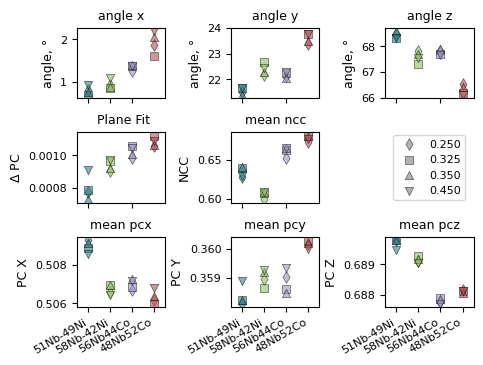

In [ ]:
fig,ax = plt.subplots(3,3,layout='tight',figsize=(12*cm,9*cm))
ax = ax.flatten()
axNum=0
MarkerList=["d","s","^","v"]
dfAll["uniqueSampleAndPhase"] = dfAll["Sample"] + "_" + dfAll["Phase_IL"]
pNum = 0
for plotProperty in plotProperties:
                # plottedSamples.append()
    plottedSamples = {}
    # axNum=0
    sampleNum =0
    # plottedSampleList = []
    # uniqueMapNum = {}
    xValues =[]
    plottedSamples = []
    legend_handles  = []

    for sample in dfAll["Sample"].unique():
        phaseNum=0
        dfPlot = dfAll[dfAll["Sample"]==sample]
        for phase in dfPlot["Phase_IL"].unique():
            dfPlotPhase = dfPlot[dfPlot["Phase_IL"]==phase]
            ax[axNum].scatter(sampleNum,dfPlotPhase[plotProperty],marker = MarkerList[phaseNum],color=colorList[sampleNum][1],label=f"{phase}",edgecolor='black',linewidth=0.5,alpha=0.6) # add the sample name later manually
            if sampleNum ==0:
                legend_handle = ax[axNum].scatter(sampleNum-3,dfPlotPhase[plotProperty],marker = MarkerList[phaseNum],color="grey",label=f"{phase}",edgecolor='black',linewidth=0.5,alpha=0.6) # add the sample name later manually
                legend_handles.append(legend_handle)
            # else:
            #     pass
                # ax[axNum].scatter(sampleNum,dfPlotPhase[plotProperty],marker = MarkerList[phaseNum],color=colorList[sampleNum][1],label=f"{phase}",edgecolor='black',linewidth=0.5,alpha=0.8) # add the sample name later manually

            phaseNum+=1
        xValues.append(sampleNum)
        sampleNum+=1
        plottedSamples.append(sample)
    ax[axNum].set_title(plotProperties_Label[pNum],fontsize=9)
    if axNum>4:
        ax[axNum].set_xticks(xValues)
        ax[axNum].set_xticklabels(plottedSamples,rotation=30,horizontalalignment='right')
    else:
        ax[axNum].set_xticklabels([])
    ax[axNum].set_xlim([min(xValues)-0.5, max(xValues)+0.5])
    ax[axNum].ticklabel_format()
    if axNum == 4:
        axNum+=1
    axNum+=1
    pNum+=1
# handles, labels = ax[7].get_legend_handles_labels()
# ax.legend(handles, labels)
ax[5].legend(handles=legend_handles,loc = "center",ncols=1,bbox_to_anchor=(0.5,0.5))
ax[5].set_axis_off()

ax[0].set_ylabel('angle, °')
ax[1].set_yticks([22,23,24])
ax[2].set_yticks([66,67,68])
ax[0].set_xticks([0,1,2])
# ax[3].set_stick
ax[1].set_ylabel('angle, °')
ax[2].set_ylabel('angle, °')
ax[3].set_ylabel('$\Delta$ PC')
ax[4].set_ylabel('NCC')
ax[6].set_ylabel('PC X')
ax[7].set_ylabel( 'PC Y')
ax[8].set_ylabel('PC Z')
        #, bbox_to_anchor=())
# fig.tight_layout()
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
plt.savefig(exportFolder.joinpath(f'ResultsFromPlaneFitting.png'),bbox_inches='tight',dpi=300)
plt.savefig(exportFolder.joinpath(f'ResultsFromPlaneFitting.svg'),bbox_inches='tight')
plt.savefig(exportFolder.joinpath(f'ResultsFromPlaneFitting.pdf'),bbox_inches='tight')

In [ ]:
dfPlot

,angle_x,angle_y,angle_z,meanDev_PlaneFit,meanDev_spatialFit,mean_pcx,mean_pcy,mean_pcz,Sample,Phase,Phase_IL,mean_ncc,uniqueSampleAndPhase
0,1.874461,23.369856,66.546083,0.001058,0.001860,0.506187,0.360178,0.688161,48Nb52Co,NbCo_a4.92_c26.25_LowNb_6c2-0.250_3aNb-1.000__...,0.250,0.673036,48Nb52Co_0.250
0,1.606957,23.780604,66.158401,0.001121,0.001850,0.505972,0.360305,0.688117,48Nb52Co,NbCo_a4.92_c26.25_LowNb_6c2-0.325_3aNb-1.000__...,0.325,0.680925,48Nb52Co_0.325
0,2.052035,23.490186,66.409499,0.001065,0.001802,0.506401,0.360208,0.688052,48Nb52Co,NbCo_a4.92_c26.25_LowNb_6c2-0.350_3aNb-1.000__...,0.350,0.681478,48Nb52Co_0.350
0,2.194464,23.781231,66.105144,0.001085,0.001864,0.506809,0.359999,0.688126,48Nb52Co,NbCo_a4.92_c26.25_LowNb_6c2-0.450_3aNb-1.000__...,0.450,0.676824,48Nb52Co_0.450


In [ ]:
dfPlotPhase

,angle_x,angle_y,angle_z,meanDev_PlaneFit,meanDev_spatialFit,mean_pcx,mean_pcy,mean_pcz,Sample,Phase,Phase_IL,mean_ncc,uniqueSampleAndPhase
0,2.194464,23.781231,66.105144,0.001085,0.001864,0.506809,0.359999,0.688126,48Nb52Co,NbCo_a4.92_c26.25_LowNb_6c2-0.450_3aNb-1.000__...,0.450,0.676824,48Nb52Co_0.450
